In [11]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
# colab -> Colab CPU -> Open terminal -> mkdir data -> cd data
# github 의 raw data 주소 확인
# wget https://github.com/code-archive-git/ai/raw/refs/heads/main/machine_learning/data/make_wave.npz

In [12]:
arr = np.load('/content/data/make_wave.npz')
print(list(arr.keys()))
x = arr['x']
y = arr['y']
print(x.shape)
print(y.shape)

['x', 'y']
(40, 1)
(40,)


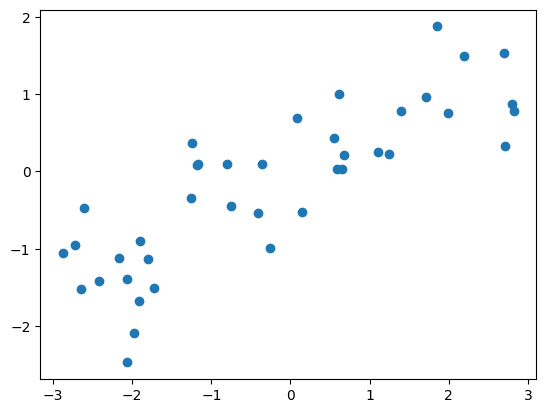

In [13]:
plt.scatter(x,y)
plt.show()

In [14]:
x_train, x_test, y_train, y_test=train_test_split(x,y,random_state=33)

model = KNeighborsRegressor(n_neighbors=2).fit(x_train, y_train)
score = model.score(x_test, y_test)
print(f'socre : {score:.2f}')

socre : 0.69


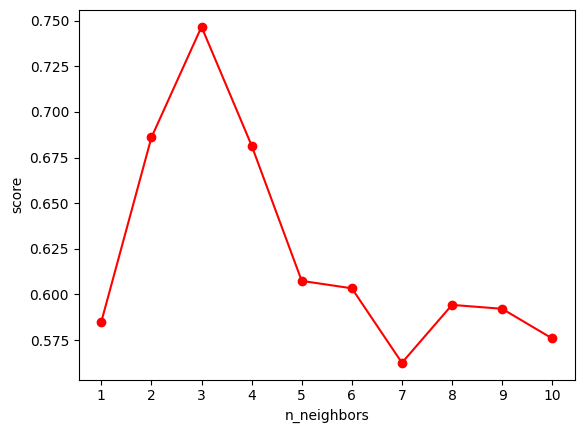

In [15]:
# neighbors_n 1~10 중 어느정도가 적당한지 테스트
neighbors_n = range(1,11)
scores = []

for n in  neighbors_n:
  model = KNeighborsRegressor(n_neighbors=n).fit(x_train, y_train)
  score = model.score(x_test, y_test)
  scores.append(score)
  # print(f'n_neighbors={n}s socre : {score:.2f}')

plt.plot(neighbors_n, scores, 'ro-')
plt.xticks(neighbors_n)
plt.xlabel('n_neighbors')
plt.ylabel('score')
plt.show()

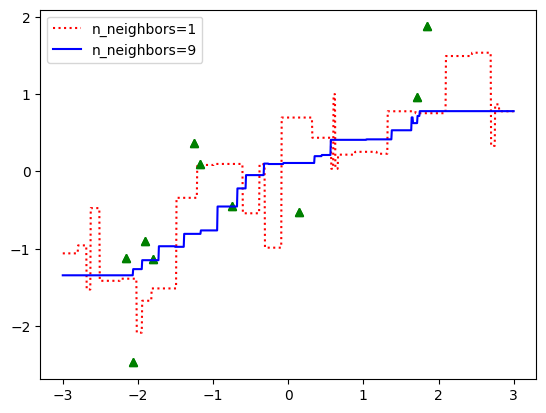

In [ ]:
import numpy as np

# 1. 테스트 데이터는 이렇다.
#plt.plot(x_test,y_test,'^')
#plt.show()

# 2. x 의 값을 -3~3 까지 세밀하게 만들어 주자
#line = np.linspace(-3,3,1000)
#print(line.shape) # 1차원 리스트(1000,)

#3. 예측 함수에 들어갈 x 값은 2차원 리스트이다.
#입력값의 종류(feature)가 여러개 일수 있고, 데이터도 여러개일수 있어서

#4. 그래서 reshape 함수를 통해 2차원 리스트로 강제 변경 해 준다.
# [0,1,2,3] -> [[0][1][2][3]]
line = np.linspace(-3,3,1000).reshape(-1,1) # 무한대층(데이터 갯수)과 1개호(특성 수)
#print(line.shape) # 2차원 리스트(1000,1)

# 5. 이걸로 예측을 시켜보자, 이웃수는 1,3,9 로 측정해 보자
for n,c in zip([1,9],[':r','-b']):
  model = KNeighborsRegressor(n_neighbors=n).fit(x_train, y_train)
  plt.plot(x_test,y_test,'^g')
  result = model.predict(line)
  plt.plot(line, result,c,label=f'n_neighbors={n}')
plt.legend()
plt.show()